In [7]:
%pip install pandas matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.8 MB 5.3 MB/s eta 0:00:02
   ----- ---------------------------------- 1.3/9.8 MB 4.2 MB/s eta 0:00:03
   --------- ------------------------------ 2.4/9.8 MB 4.1 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.8 MB 4.9 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.8 MB 5.2 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.8 MB 5.2 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.8 MB 5.2 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.8 MB 3.4 MB/s eta 0:00:02
   --------------------------- ------------ 6.8/9.8 MB 3.7 MB/s eta 0:00:01
   ------------------------------- -------- 7

In [8]:
import sqlite3
import pandas  as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
conn = sqlite3.connect('enterprise_database (1).db')

In [10]:
cursor = conn.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
print(cursor.fetchall())

[('users',)]


In [11]:
check = pd.read_sql_query("SELECT * FROM users WHERE user_id = 'U-00000'", conn)
print(check)

   user_id          name     status           updated_at
0  U-00000  User_U-00000    Pending  2023-01-01 10:00:00
1  U-00000  User_U-00000     Active  2023-01-19 14:00:00
2  U-00000  User_U-00000  Suspended  2023-02-28 09:00:00


In [12]:
query = """
SELECT user_id, name, status, updated_at
FROM (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY updated_at DESC) AS rn
    FROM users
) ranked
WHERE rn = 1 AND status = 'Active'
"""

df_active_users = pd.read_sql_query(query, conn)
print(df_active_users.shape)
print(df_active_users.head())

(14183, 4)
   user_id          name  status           updated_at
0  U-00001  User_U-00001  Active  2023-01-28 14:00:00
1  U-00003  User_U-00003  Active  2023-01-22 14:00:00
2  U-00005  User_U-00005  Active  2023-01-17 14:00:00
3  U-00006  User_U-00006  Active  2023-01-05 14:00:00
4  U-00007  User_U-00007  Active  2023-01-27 14:00:00


In [13]:
print(df_active_users[df_active_users['user_id'] == 'U-00000'])

Empty DataFrame
Columns: [user_id, name, status, updated_at]
Index: []


In [14]:
df_active_users = pd.read_sql_query(query, conn)
print(df_active_users.shape)
print(df_active_users['status'].unique())

(14183, 4)
<StringArray>
['Active']
Length: 1, dtype: str


In [15]:
df_active_users = pd.read_sql_query(query, conn)
conn.close()

In [16]:
print(df_active_users.shape)
print(df_active_users['status'].unique())
print(df_active_users.head())

(14183, 4)
<StringArray>
['Active']
Length: 1, dtype: str
   user_id          name  status           updated_at
0  U-00001  User_U-00001  Active  2023-01-28 14:00:00
1  U-00003  User_U-00003  Active  2023-01-22 14:00:00
2  U-00005  User_U-00005  Active  2023-01-17 14:00:00
3  U-00006  User_U-00006  Active  2023-01-05 14:00:00
4  U-00007  User_U-00007  Active  2023-01-27 14:00:00


In [17]:
with open('server_logs (1).txt', 'r', encoding='utf-8') as f:
    log_lines = f.readlines()

df_logs = pd.DataFrame({'raw': log_lines})
print(df_logs.shape)
print(df_logs.head())
print(df_logs['raw'].iloc[0])

(100001, 1)
                                                 raw
0                                   Raw_Server_Log\n
1  "[2023-03-15 00:00:00] INFO: Transaction proce...
2  "[2023-09-09 00:00:00] ERROR: Transaction proc...
3  "[2023-05-09 00:00:00] INFO: Transaction proce...
4  "[2023-10-21 00:00:00] INFO: Transaction proce...
Raw_Server_Log



In [18]:
df_logs = df_logs[~df_logs['raw'].str.contains('ERROR')]
print(df_logs.shape)

(94903, 1)


In [19]:
print(df_logs['raw'].str.contains('ERROR').sum())

0


In [20]:
pattern = r'\[(?P<date>\d{4}-\d{2}-\d{2}).*?"{1,2}u"{1,2}:"{1,2}(?P<user_id>U-\d+)"{1,2}.*?"{1,2}item_code"{1,2}:"{1,2}(?P<product_id>PRD-\d+)"{1,2}.*?"{1,2}eur_val"{1,2}:(?P<euro_value>[\d.]+)'

extracted_data = df_logs['raw'].str.extract(pattern)

print(extracted_data.shape)
print(extracted_data.isna().sum())
print(extracted_data.head())

(94903, 4)
date          1
user_id       1
product_id    1
euro_value    1
dtype: int64
         date  user_id product_id euro_value
0         NaN      NaN        NaN        NaN
1  2023-03-15  U-19484    PRD-874    3404.44
3  2023-05-09  U-18932    PRD-905    3406.21
4  2023-10-21  U-15882    PRD-284     164.08
5  2023-01-10  U-22781    PRD-665       26.8


In [21]:
extracted_data = extracted_data.dropna().reset_index(drop=True)
print(extracted_data.shape)
print(extracted_data.isna().sum())
print(extracted_data.head())

(94902, 4)
date          0
user_id       0
product_id    0
euro_value    0
dtype: int64
         date  user_id product_id euro_value
0  2023-03-15  U-19484    PRD-874    3404.44
1  2023-05-09  U-18932    PRD-905    3406.21
2  2023-10-21  U-15882    PRD-284     164.08
3  2023-01-10  U-22781    PRD-665       26.8
4  2023-05-23  U-13348    PRD-589    4964.77


In [22]:
extracted_data['date'] = pd.to_datetime(extracted_data['date'])
extracted_data['euro_value'] = extracted_data['euro_value'].astype(float)

print(extracted_data.dtypes)

date          datetime64[us]
user_id                  str
product_id               str
euro_value           float64
dtype: object


In [23]:
rates = pd.read_csv('daily_exchange_rates (1).csv')
print(rates.shape)
print(rates.dtypes)
print(rates.head())

(365, 2)
Date              str
EUR_to_USD    float64
dtype: object
         Date  EUR_to_USD
0  2023-01-01    1.124836
1  2023-01-02    1.093087
2  2023-01-03    1.132384
3  2023-01-04    1.176151
4  2023-01-05    1.088292


In [24]:
rates['Date'] = pd.to_datetime(rates['Date'])
rates = rates.sort_values('Date').reset_index(drop=True)

print("Missing rates before fill:", rates['EUR_to_USD'].isna().sum())

rates['EUR_to_USD'] = rates['EUR_to_USD'].ffill()

print("Missing rates after fill:", rates['EUR_to_USD'].isna().sum())
print(rates.head(10))

Missing rates before fill: 104
Missing rates after fill: 0
        Date  EUR_to_USD
0 2023-01-01    1.124836
1 2023-01-02    1.093087
2 2023-01-03    1.132384
3 2023-01-04    1.176151
4 2023-01-05    1.088292
5 2023-01-06    1.088292
6 2023-01-07    1.088292
7 2023-01-08    1.138372
8 2023-01-09    1.076526
9 2023-01-10    1.127128


In [25]:
merged = extracted_data.merge(rates, left_on='date', right_on='Date', how='left')
print(merged.shape)
print(merged.isna().sum())
print(merged.head())

(94902, 6)
date          0
user_id       0
product_id    0
euro_value    0
Date          0
EUR_to_USD    0
dtype: int64
        date  user_id product_id  euro_value       Date  EUR_to_USD
0 2023-03-15  U-19484    PRD-874     3404.44 2023-03-15    1.178232
1 2023-05-09  U-18932    PRD-905     3406.21 2023-05-09    1.104983
2 2023-10-21  U-15882    PRD-284      164.08 2023-10-21    1.075350
3 2023-01-10  U-22781    PRD-665       26.80 2023-01-10    1.127128
4 2023-05-23  U-13348    PRD-589     4964.77 2023-05-23    1.019626


In [26]:
df_final = merged.merge(df_active_users, on='user_id', how='inner')
print(df_final.shape)
print(df_final.isna().sum())
print(df_final.head())

(53899, 9)
date          0
user_id       0
product_id    0
euro_value    0
Date          0
EUR_to_USD    0
name          0
status        0
updated_at    0
dtype: int64
        date  user_id product_id  euro_value       Date  EUR_to_USD  \
0 2023-03-15  U-19484    PRD-874     3404.44 2023-03-15    1.178232   
1 2023-10-21  U-15882    PRD-284      164.08 2023-10-21    1.075350   
2 2023-01-10  U-22781    PRD-665       26.80 2023-01-10    1.127128   
3 2023-10-20  U-22062    PRD-363       48.63 2023-10-20    1.075350   
4 2023-12-02  U-22146    PRD-223      960.60 2023-12-02    1.066142   

           name  status           updated_at  
0  User_U-19484  Active  2023-01-11 14:00:00  
1  User_U-15882  Active  2023-01-16 14:00:00  
2  User_U-22781  Active  2023-01-07 14:00:00  
3  User_U-22062  Active  2023-01-05 14:00:00  
4  User_U-22146  Active  2023-01-18 14:00:00  


In [27]:
print(df_final['status'].unique())

<StringArray>
['Active']
Length: 1, dtype: str


In [28]:
df_final['USD_Revenue'] = df_final['euro_value'] * df_final['EUR_to_USD']
print(df_final[['euro_value', 'EUR_to_USD', 'USD_Revenue']].head())
print(df_final.shape)

   euro_value  EUR_to_USD  USD_Revenue
0     3404.44    1.178232  4011.220772
1      164.08    1.075350   176.443420
2       26.80    1.127128    30.207030
3       48.63    1.075350    52.294268
4      960.60    1.066142  1024.135923
(53899, 10)


In [29]:
df_final = merged.merge(df_active_users, on='user_id', how='inner')
df_final['USD_Revenue'] = df_final['euro_value'] * df_final['EUR_to_USD']

print(df_final.shape)
print(df_final[['euro_value', 'EUR_to_USD', 'USD_Revenue']].head())

(53899, 10)
   euro_value  EUR_to_USD  USD_Revenue
0     3404.44    1.178232  4011.220772
1      164.08    1.075350   176.443420
2       26.80    1.127128    30.207030
3       48.63    1.075350    52.294268
4      960.60    1.066142  1024.135923


In [30]:
df_final['month'] = df_final['date'].dt.to_period('M')
monthly_revenue = df_final.groupby('month')['USD_Revenue'].sum().reset_index()
monthly_revenue['month'] = monthly_revenue['month'].astype(str)
print(monthly_revenue)

      month   USD_Revenue
0   2023-01  1.284176e+07
1   2023-02  1.143613e+07
2   2023-03  1.234893e+07
3   2023-04  1.201538e+07
4   2023-05  1.233364e+07
5   2023-06  1.208436e+07
6   2023-07  1.244416e+07
7   2023-08  1.281273e+07
8   2023-09  1.222895e+07
9   2023-10  1.250133e+07
10  2023-11  1.258822e+07
11  2023-12  1.263902e+07


In [31]:
top_customers = df_final.groupby('name')['USD_Revenue'].sum().sort_values(ascending=False).head(5).reset_index()
print(top_customers)

           name   USD_Revenue
0  User_U-06582  40050.988262
1  User_U-23313  39555.806629
2  User_U-03805  39529.945085
3  User_U-20018  38649.965242
4  User_U-06489  38629.142146


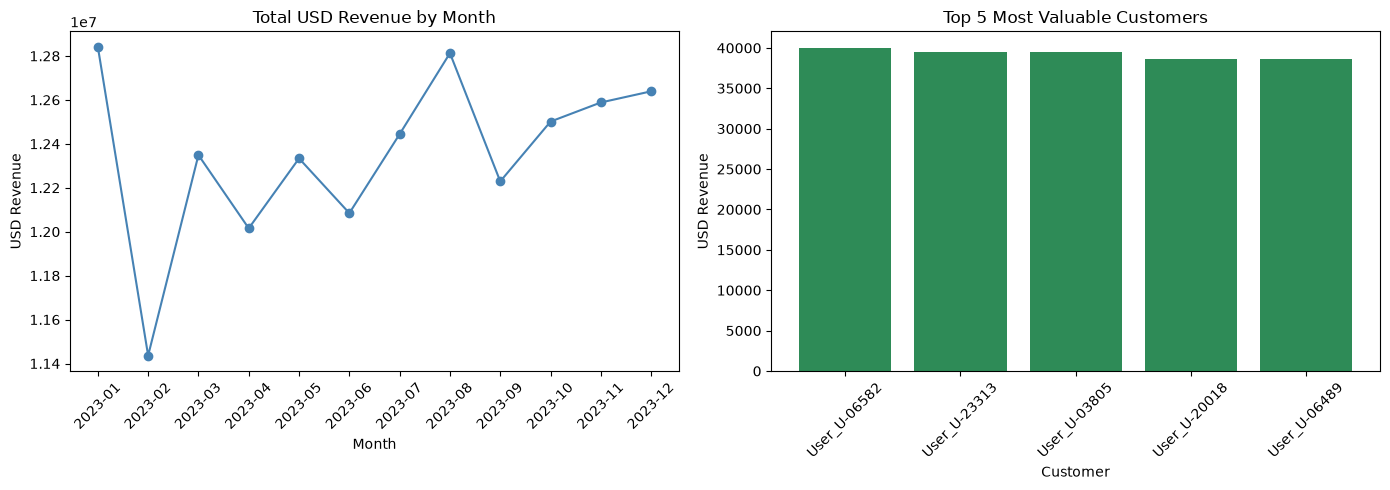

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(monthly_revenue['month'], monthly_revenue['USD_Revenue'], marker='o', color='steelblue')
axes[0].set_title('Total USD Revenue by Month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('USD Revenue')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(top_customers['name'], top_customers['USD_Revenue'], color='seagreen')
axes[1].set_title('Top 5 Most Valuable Customers')
axes[1].set_xlabel('Customer')
axes[1].set_ylabel('USD Revenue')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [33]:
plt.suptitle('CFO Financial Dashboard - Q1-Q4 2023', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>